In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/notebooks/mugdhanaik/step6-updated/__results__.html
/kaggle/input/notebooks/mugdhanaik/step6-updated/__notebook__.ipynb
/kaggle/input/notebooks/mugdhanaik/step6-updated/__output__.json
/kaggle/input/notebooks/mugdhanaik/step6-updated/custom.css
/kaggle/input/datasets/reubensuju/celeb-df-v2/List_of_testing_videos.txt
/kaggle/input/datasets/reubensuju/celeb-df-v2/Celeb-real/id0_0000.mp4
/kaggle/input/datasets/reubensuju/celeb-df-v2/Celeb-real/id0_0001.mp4
/kaggle/input/datasets/reubensuju/celeb-df-v2/Celeb-real/id0_0002.mp4
/kaggle/input/datasets/reubensuju/celeb-df-v2/Celeb-real/id0_0003.mp4
/kaggle/input/datasets/reubensuju/celeb-df-v2/Celeb-real/id0_0004.mp4
/kaggle/input/datasets/reubensuju/celeb-df-v2/Celeb-real/id0_0005.mp4
/kaggle/input/datasets/reubensuju/celeb-df-v2/Celeb-real/id0_0006.mp4
/kaggle/input/datasets/reubensuju/celeb-df-v2/Celeb-real/id0_0007.mp4
/kaggle/input/datasets/reubensuju/celeb-df-v2/Celeb-real/id0_0008.mp4
/kaggle/input/datasets/reubensuju/cele

In [2]:
# ============================================================
# ENVIRONMENT SETUP — run this first, every session
# --no-deps is deliberate: prevents facenet-pytorch from pulling in a
# different numpy/torch/torchvision/Pillow than what Kaggle already has
# installed together (and already mutually compatible). Letting pip's
# resolver touch those is what caused the numpy ABI corruption and the
# Pillow/torchvision conflict in earlier attempts.
# ============================================================
!pip install -q --no-deps facenet-pytorch==2.6.0

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.9/1.9 MB 45.2 MB/s eta 0:00:00


In [3]:
# ============================================================
# PATCH: restore is_directory/is_path to PIL._util BEFORE importing
# torchvision. Newer Pillow (needed by facenet-pytorch) removed these,
# which breaks torchvision's ImageFont import chain. This is not
# fixable by picking a Pillow/torchvision version — no compatible pair
# exists — so we patch the two missing functions back in directly.
# ============================================================
import os
import PIL._util as _util

if not hasattr(_util, "is_directory"):
    _util.is_directory = lambda path: os.path.isdir(path)
if not hasattr(_util, "is_path"):
    _util.is_path = lambda path: isinstance(path, (bytes, str, os.PathLike))

import torch, torchvision, PIL
import importlib.metadata

print("Torch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("Pillow:", PIL.__version__)
print("facenet-pytorch:", importlib.metadata.version("facenet-pytorch"))
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

from facenet_pytorch import MTCNN
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
_test_mtcnn = MTCNN(keep_all=True, device=device)
print("facenet-pytorch import + MTCNN init: OK")

Torch: 2.11.0+cu128
Torchvision: 0.26.0+cu128
Pillow: 12.3.0
facenet-pytorch: 2.6.0
CUDA available: True
GPU: Tesla T4
facenet-pytorch import + MTCNN init: OK


In [4]:
import os, sys, glob, time
import numpy as np
import pandas as pd

REPO_URL = "https://github.com/Mugdha-Naik/deepfake-detector-project.git"
REPO_DIR = "/kaggle/working/repo"
if not os.path.exists(REPO_DIR):
    os.system(f"git clone {REPO_URL} {REPO_DIR}")
else:
    os.system(f"cd {REPO_DIR} && git pull")
sys.path.append(REPO_DIR)

from utils import (load_mtcnn, extract_faces_from_video, apply_quality_filters,
                   count_sampled_frames, CELEB_ROOT, FF_ROOT)
try:
    from utils import FRAME_INTERVAL
except ImportError:
    FRAME_INTERVAL = 10
    print("FRAME_INTERVAL is not exported by utils.py; assuming 10 (the Step 4 setting).")
print("utils loaded. FRAME_INTERVAL =", FRAME_INTERVAL)

Cloning into '/kaggle/working/repo'...


utils loaded. FRAME_INTERVAL = 10


In [5]:
from PIL import Image
from tqdm.auto import tqdm
print("Celeb-DF exists:", os.path.exists(CELEB_ROOT))
print("FF++ exists:", os.path.exists(FF_ROOT))

Celeb-DF exists: True
FF++ exists: True


In [6]:
# ============================================================
# LOAD THE SPLIT MAP (produced by Step 6b, committed in the repo)
# ============================================================
hits = (glob.glob("/kaggle/input/video-split-map/**/video_split_map.csv", recursive=True)
        + glob.glob("/kaggle/input/datasets/*/video-split-map/**/video_split_map.csv", recursive=True))
hits = sorted(set(hits))
assert len(hits) == 1, f"expected exactly one video_split_map.csv, found: {hits}"
SPLIT_MAP_PATH = hits[0]
smap = pd.read_csv(SPLIT_MAP_PATH)
print("Split map:", SPLIT_MAP_PATH, "| videos:", len(smap))
print(pd.crosstab([smap["dataset"], smap["label_name"]], smap["split"]))

# Only videos with a usable split can be sampled
pool_all = smap[smap["split"].isin(["train", "val", "test"])].copy()
assert not pool_all.empty

Split map: /kaggle/input/datasets/mugdhanaik/video-split-map/video_split_map.csv | videos: 13529
split                       excluded  test  train  unused  val
dataset         label_name                                    
Celeb-DF        FAKE               0   340      0    5299    0
                REAL               0   178      0     712    0
FaceForensics++ FAKE            1000   700   3600       0  700
                REAL               0   140    720       0  140


In [7]:
# ============================================================
# SAMPLE PLAN  (dataset, label, split) -> number of videos
# Total below = 960 videos. FF++ test and Celeb-DF are kept larger because
# test-set size controls how wide the confidence intervals are.
# ============================================================
SAMPLE_PLAN = {
    ("FaceForensics++", "REAL", "train"): 200,
    ("FaceForensics++", "FAKE", "train"): 200,
    ("FaceForensics++", "REAL", "val"):    30,
    ("FaceForensics++", "FAKE", "val"):    30,
    ("FaceForensics++", "REAL", "test"):  100,
    ("FaceForensics++", "FAKE", "test"):  100,
    ("Celeb-DF",        "REAL", "test"):  150,
    ("Celeb-DF",        "FAKE", "test"):  150,
}
MAX_FACES_PER_VIDEO = 30      # cap; videos with fewer faces keep all of them
SEED = 42

def allocate(n, avail):
    """Spread n picks evenly across groups (e.g. manipulation methods),
    never taking more than a group has; leftovers go to groups with room."""
    alloc = {k: 0 for k in avail}
    remaining = min(n, sum(avail.values()))
    while remaining > 0:
        open_keys = [k for k in avail if alloc[k] < avail[k]]
        share = max(1, remaining // len(open_keys))
        for k in open_keys:
            take = min(share, avail[k] - alloc[k], remaining)
            alloc[k] += take
            remaining -= take
            if remaining == 0:
                break
    return alloc

parts = []
for (ds, lab, spl), n in SAMPLE_PLAN.items():
    grp = pool_all[(pool_all["dataset"] == ds) & (pool_all["label_name"] == lab) & (pool_all["split"] == spl)]
    avail = grp.groupby("method").size().to_dict()
    alloc = allocate(n, avail)
    for meth, k in alloc.items():
        if k:
            parts.append(grp[grp["method"] == meth].sample(n=k, random_state=SEED))
    got = sum(alloc.values())
    if got < n:
        print(f"WARNING: {ds}/{lab}/{spl}: wanted {n}, only {got} available")

run_df = (pd.concat(parts).sample(frac=1, random_state=SEED)   # shuffled: a partial run stays balanced
            .reset_index(drop=True))
print("Total videos selected:", len(run_df))
print(run_df.groupby(["dataset", "label_name", "split"]).size())
print()
print(run_df[run_df["dataset"] == "FaceForensics++"].groupby(["label_name", "split", "method"]).size().unstack(fill_value=0))

Total videos selected: 960
dataset          label_name  split
Celeb-DF         FAKE        test     150
                 REAL        test     150
FaceForensics++  FAKE        test     100
                             train    200
                             val       30
                 REAL        test     100
                             train    200
                             val       30
dtype: int64

method            Deepfakes  Face2Face  FaceShifter  FaceSwap  NeuralTextures  \
label_name split                                                                
FAKE       test          20         20           20        20              20   
           train         40         40           40        40              40   
           val            6          6            6         6               6   
REAL       test           0          0            0         0               0   
           train          0          0            0         0               0   
           val       

In [8]:
mtcnn, device = load_mtcnn()

OUTPUT_DIR = "/kaggle/working/step5_faces"
FACES_DIR = os.path.join(OUTPUT_DIR, "faces")
os.makedirs(FACES_DIR, exist_ok=True)
STEP5_DIR = "/kaggle/working/step5_quality"
os.makedirs(STEP5_DIR, exist_ok=True)
print("Faces directory:", FACES_DIR)

MTCNN loaded. Device: cuda
Faces directory: /kaggle/working/step5_faces/faces


In [9]:
# ============================================================
# MAIN EXTRACTION LOOP
# - per-video try/except: a broken video is logged, the run continues
# - faces capped per video (evenly spaced); extra crops are deleted from disk
# - partial results saved every 50 videos
# ============================================================
all_records, video_stats, failed = [], [], []
t0 = time.time()

for idx, row in tqdm(run_df.iterrows(), total=len(run_df), desc="Step 5 extraction"):
    video_path = row["kaggle_path"]
    video_id = f"video_{idx}"
    t_vid = time.time()
    try:
        if not os.path.exists(video_path):
            raise FileNotFoundError(video_path)

        frames_sampled = count_sampled_frames(video_path, FRAME_INTERVAL)

        records = extract_faces_from_video(
            video_path=video_path, label_name=row["label_name"], faces_dir=FACES_DIR,
            video_id=video_id, mtcnn=mtcnn, sampling="interval")

        records = sorted(records, key=lambda r: r["frame_number"])
        n_detected = len(records)

        if n_detected > MAX_FACES_PER_VIDEO:
            keep_idx = set(np.linspace(0, n_detected - 1, MAX_FACES_PER_VIDEO).round().astype(int).tolist())
            kept = [r for i, r in enumerate(records) if i in keep_idx]
            for i, r in enumerate(records):
                if i not in keep_idx and os.path.exists(r["face_path"]):
                    os.remove(r["face_path"])
        else:
            kept = records

        for r in kept:
            r["dataset"], r["split"] = row["dataset"], row["split"]
            r["method"], r["video_id"] = row["method"], video_id
        all_records.extend(kept)

        video_stats.append({
            "video_id": video_id, "video_path": video_path, "dataset": row["dataset"],
            "label_name": row["label_name"], "split": row["split"], "method": row["method"],
            "frames_sampled_est": frames_sampled, "faces_detected": n_detected,
            "faces_kept": len(kept), "capped": n_detected > MAX_FACES_PER_VIDEO,
            "seconds": round(time.time() - t_vid, 1)})
    except Exception as e:
        failed.append({"video_id": video_id, "video_path": video_path, "dataset": row["dataset"],
                       "label_name": row["label_name"], "split": row["split"],
                       "error": f"{type(e).__name__}: {e}"})

    if (idx + 1) % 50 == 0:
        pd.DataFrame(all_records).to_csv(os.path.join(STEP5_DIR, "partial_records.csv"), index=False)
        done = idx + 1
        eta_min = (time.time() - t0) / done * (len(run_df) - done) / 60
        print(f"[{done}/{len(run_df)}] faces so far: {len(all_records)} | failed: {len(failed)} | ETA ~{eta_min:.0f} min")

step5_df = pd.DataFrame(all_records)
stats_df = pd.DataFrame(video_stats)
failed_df = pd.DataFrame(failed)

print("=" * 60)
print("EXTRACTION COMPLETE in", round((time.time() - t0) / 60, 1), "min")
print("Videos processed:", len(stats_df), "| failed:", len(failed_df))
print("Face crops kept:", len(step5_df))
print(step5_df.groupby(["dataset", "label_name", "split"]).size())

Step 5 extraction:   0%|          | 0/960 [00:00<?, ?it/s]

[50/960] faces so far: 1487 | failed: 0 | ETA ~242 min
[100/960] faces so far: 2985 | failed: 0 | ETA ~247 min
[150/960] faces so far: 4479 | failed: 0 | ETA ~235 min
[200/960] faces so far: 5979 | failed: 0 | ETA ~220 min
[250/960] faces so far: 7476 | failed: 0 | ETA ~209 min
[300/960] faces so far: 8948 | failed: 0 | ETA ~193 min
[350/960] faces so far: 10438 | failed: 0 | ETA ~181 min
[400/960] faces so far: 11918 | failed: 0 | ETA ~165 min
[450/960] faces so far: 13415 | failed: 0 | ETA ~151 min
[500/960] faces so far: 14897 | failed: 0 | ETA ~135 min
[550/960] faces so far: 16390 | failed: 0 | ETA ~119 min
[600/960] faces so far: 17885 | failed: 0 | ETA ~103 min
[650/960] faces so far: 19383 | failed: 0 | ETA ~88 min
[700/960] faces so far: 20877 | failed: 0 | ETA ~74 min
[750/960] faces so far: 22355 | failed: 0 | ETA ~59 min
[800/960] faces so far: 23844 | failed: 0 | ETA ~44 min
[850/960] faces so far: 25344 | failed: 0 | ETA ~31 min
[900/960] faces so far: 26833 | failed: 0 |

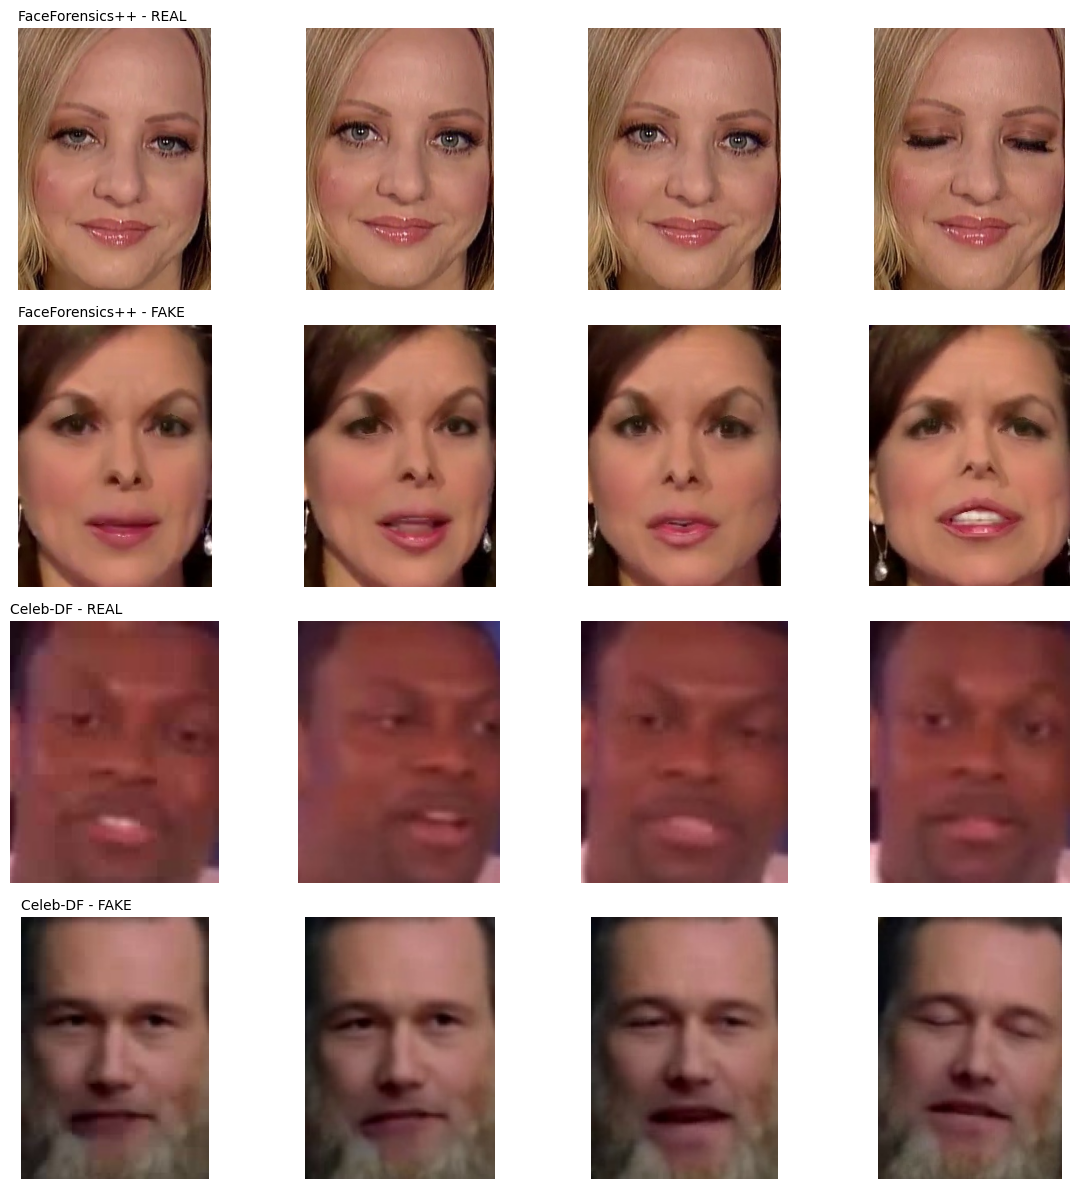

In [10]:
# ============================================================
# SANITY CHECK — view saved crops for each dataset x label group
# ============================================================
import matplotlib.pyplot as plt
groups = [("FaceForensics++", "REAL"), ("FaceForensics++", "FAKE"), ("Celeb-DF", "REAL"), ("Celeb-DF", "FAKE")]
N_PER_ROW = 4
fig, axes = plt.subplots(len(groups), N_PER_ROW, figsize=(12, 12))
for r, (ds, lab) in enumerate(groups):
    paths = step5_df[(step5_df["dataset"] == ds) & (step5_df["label_name"] == lab)]["face_path"].head(N_PER_ROW).tolist()
    for c in range(N_PER_ROW):
        ax = axes[r][c]; ax.axis("off")
        if c < len(paths):
            ax.imshow(Image.open(paths[c]))
        if c == 0:
            ax.set_title(f"{ds} - {lab}", fontsize=10, loc="left")
plt.tight_layout(); plt.show()

In [11]:
# ============================================================
# QUALITY FLAGGING  (blur = flag only; size is the only filter)
# ============================================================
step5_df, _ = apply_quality_filters(step5_df)
step5_df["quality_pass"] = step5_df["size_pass"]
quality_filtered_df = step5_df[step5_df["quality_pass"]].copy()

total_in = len(step5_df)
flagged_blur = int((~step5_df["blur_pass"]).sum())
dropped_size = int((~step5_df["size_pass"]).sum())
remaining = int(step5_df["quality_pass"].sum())
print("Total faces in:", total_in)
print("Flagged as low-blur (kept):", flagged_blur)
print("Dropped due to size:", dropped_size)
print("Remaining:", remaining)

# cross-check against the per-video stats (Step 8 relies on this)
assert total_in == int(stats_df["faces_kept"].sum()), "face rows != sum of faces_kept in video stats"

Total faces in: 28623
Flagged as low-blur (kept): 14222
Dropped due to size: 439
Remaining: 28184


In [12]:
blur_stats = (step5_df.groupby(["dataset", "label_name"])["blur_score"]
                .describe(percentiles=[.1, .25, .5, .75, .9]).round(1))
blur_stats["blur_pass_rate"] = step5_df.groupby(["dataset", "label_name"])["blur_pass"].mean().round(2)
blur_stats

count   mean    std  min   10%   25%   50%  \
dataset         label_name                                                
Celeb-DF        FAKE        4389.0   35.7   34.1  7.1  15.3  20.3  28.0   
                REAL        4437.0   46.9   33.4  6.7  18.8  26.0  37.1   
FaceForensics++ FAKE        9897.0   98.3  111.2  4.2  13.7  25.0  62.3   
                REAL        9900.0  141.6  149.1  2.9  20.7  37.4  90.2   

                              75%    90%     max  blur_pass_rate  
dataset         label_name                                        
Celeb-DF        FAKE         42.6   58.9   657.7            0.17  
                REAL         57.0   87.3   289.4            0.31  
FaceForensics++ FAKE        126.2  228.0   840.6            0.56  
                REAL        191.2  336.3  1257.3            0.68

In [13]:
# ============================================================
# SUMMARIES + SAVE
# ============================================================
class_summary = []
for (ds, label, spl), g in step5_df.groupby(["dataset", "label_name", "split"]):
    kept = g[g["quality_pass"]]
    class_summary.append({
        "dataset": ds, "class": label, "split": spl, "videos": g["video_id"].nunique(),
        "total_in": len(g), "flagged_blur_kept": int((~g["blur_pass"]).sum()),
        "dropped_size": int((~g["size_pass"]).sum()), "remaining": len(kept)})
class_summary_df = pd.DataFrame(class_summary)

overall_summary = pd.DataFrame([{
    "total_faces_in": total_in, "flagged_blur_kept": flagged_blur,
    "dropped_size": dropped_size, "remaining": remaining,
    "percentage_dropped": round((total_in - remaining) / total_in * 100, 2) if total_in else 0.0,
    "max_faces_per_video": MAX_FACES_PER_VIDEO, "frame_interval": FRAME_INTERVAL, "seed": SEED}])

outputs = {
    "quality_filtered_faces.csv": quality_filtered_df,
    "step5_class_summary.csv": class_summary_df,
    "step5_overall_summary.csv": overall_summary,
    "step5_video_stats.csv": stats_df,
    "step5_failed_videos.csv": failed_df if len(failed_df) else pd.DataFrame(columns=["video_id","video_path","dataset","label_name","split","error"]),
}
for name, frame in outputs.items():
    frame.to_csv(os.path.join(STEP5_DIR, name), index=False)
blur_stats.to_csv(os.path.join(STEP5_DIR, "step5_blur_stats.csv"))

print("Saved to", STEP5_DIR)
for name in list(outputs) + ["step5_blur_stats.csv"]:
    print(" ", name)
class_summary_df

Saved to /kaggle/working/step5_quality
  quality_filtered_faces.csv
  step5_class_summary.csv
  step5_overall_summary.csv
  step5_video_stats.csv
  step5_failed_videos.csv
  step5_blur_stats.csv


,dataset,class,split,videos,total_in,flagged_blur_kept,dropped_size,remaining
0,Celeb-DF,FAKE,test,150,4389,3649,7,4382
1,Celeb-DF,REAL,test,150,4437,3052,56,4381
2,FaceForensics++,FAKE,test,100,3000,1499,0,3000
3,FaceForensics++,FAKE,train,200,6000,2463,150,5850
4,FaceForensics++,FAKE,val,30,897,344,0,897
5,FaceForensics++,REAL,test,100,3000,935,117,2883
6,FaceForensics++,REAL,train,200,6000,2003,109,5891
7,FaceForensics++,REAL,val,30,900,277,0,900


In [14]:
print("=" * 60)
print("STEP 5 FINAL CHECK")
print("=" * 60)
print("Final face count:", len(quality_filtered_df))

print("\nFaces per dataset x label x split:")
print(quality_filtered_df.groupby(["dataset", "label_name", "split"]).size())

print("\nVideos per dataset x label x split:")
print(quality_filtered_df.groupby(["dataset", "label_name", "split"])["video_id"].nunique())

no_face = stats_df[stats_df["faces_kept"] == 0]
print("\nVideos with zero faces:", len(no_face), "of", len(stats_df))
print("Failed videos:", len(failed_df))
if len(failed_df):
    print(failed_df["error"].value_counts().head(5))

print("\nFaces per video (after cap):")
print(stats_df.groupby(["dataset", "label_name"])["faces_kept"].describe().round(1))

# Every planned group must have faces
planned = {(d, l, s) for (d, l, s) in SAMPLE_PLAN}
final = set(map(tuple, quality_filtered_df[["dataset", "label_name", "split"]].drop_duplicates().values))
assert planned <= final, f"empty groups after extraction: {planned - final}"
# No video may sit in two splits
assert quality_filtered_df.groupby("video_id")["split"].nunique().max() == 1
print("\nAll planned groups present; no video in two splits: OK")

STEP 5 FINAL CHECK
Final face count: 28184

Faces per dataset x label x split:
dataset          label_name  split
Celeb-DF         FAKE        test     4382
                 REAL        test     4381
FaceForensics++  FAKE        test     3000
                             train    5850
                             val       897
                 REAL        test     2883
                             train    5891
                             val       900
dtype: int64

Videos per dataset x label x split:
dataset          label_name  split
Celeb-DF         FAKE        test     150
                 REAL        test     150
FaceForensics++  FAKE        test     100
                             train    195
                             val       30
                 REAL        test      98
                             train    198
                             val       30
Name: video_id, dtype: int64

Videos with zero faces: 0 of 960
Failed videos: 0

Faces per video (after cap):
           